# Uçtan Uca Pipeline Demo — Kusur Segmentasyonu + Açıklanabilirlik

Bu notebook, eğitilmiş bir segmentasyon modelinin tek bir test görseli üzerindeki uçtan uca akışını tek yerde gösterir: **görsel → model → tahmin maskesi → görselleştirme → Grad-CAM (XAI)**.

Bu, `src/train.py` ile eğitilmiş checkpoint'i (`outputs/checkpoints/{model}_best.pt`) ve `src/prepare_data.py` çıktısı split'i (`data/processed/splits.csv`) okur — yeniden eğitim yapmaz.

Önkoşul: `python src/prepare_data.py && python src/train.py --config configs/unet_baseline.yaml` bir kez çalıştırılmış olmalı.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..") / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

from augmentations import IMAGENET_MEAN, IMAGENET_STD, get_val_transform
from dataset import MVTecSegDataset
from models.factory import build_model

PROJECT_ROOT = Path("..")
CONFIG_PATH = PROJECT_ROOT / "configs" / "unet_baseline.yaml"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Cihaz: {device}")

C:\Users\ibrahim\anaconda3\envs\defect_seg_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cihaz: cuda


## 1. Config + eğitilmiş modeli yükle

In [2]:
with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)

run_name = config["model"]["name"]
image_size = config["data"]["image_size"]
checkpoint_path = PROJECT_ROOT / config["logging"]["checkpoint_dir"] / f"{run_name}_best.pt"

model = build_model(config["model"]["name"], config["model"]["encoder"], config["model"]["encoder_weights"]).to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
print(f"Model: {run_name} ({config['model']['encoder']} encoder), checkpoint: {checkpoint_path.name}")

Model: unet (resnet34 encoder), checkpoint: unet_best.pt


## 2. Test görseli → model → tahmin maskesi

Manifest'teki test split'inden kusurlu bir örnek seçip modele veriyoruz.

In [3]:
manifest_path = PROJECT_ROOT / "data" / "processed" / "splits.csv"
test_ds = MVTecSegDataset(manifest_path, "test", transform=get_val_transform(image_size))

# ilk kusurlu (maskesi bos olmayan) ornegi bul
sample_idx = 0
for i in range(len(test_ds)):
    _, mask, category = test_ds[i]
    if mask.sum() > 0:
        sample_idx = i
        break

image_t, mask_t, category = test_ds[sample_idx]
input_tensor = image_t.unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (prob > 0.5).astype(np.float32)

gt_mask = mask_t[0].numpy()
print(f"Ornek: idx={sample_idx}, kategori={category}")

Ornek: idx=0, kategori=crack


## 3. Görselleştirme: girdi / gerçek maske / tahmin

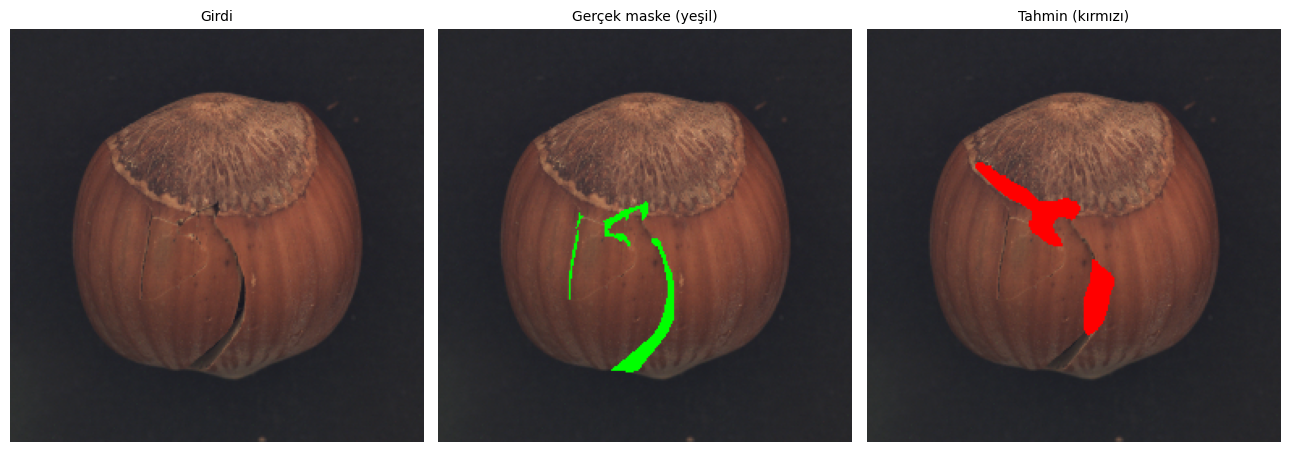

In [4]:
def denormalize(tensor_img):
    img = tensor_img.cpu().numpy().transpose(1, 2, 0)
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)


rgb_img = denormalize(image_t)
gt_overlay = rgb_img.copy()
gt_overlay[gt_mask > 0.5] = [0, 1, 0]
pred_overlay = rgb_img.copy()
pred_overlay[pred_mask > 0.5] = [1, 0, 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, img, title in zip(axes, [rgb_img, gt_overlay, pred_overlay], ["Girdi", "Gerçek maske (yeşil)", "Tahmin (kırmızı)"]):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Açıklanabilirlik (XAI): Grad-CAM

Model kusuru tespit ederken görselin neresine "baktı"? Grad-CAM, segmentasyon çıktısını hedef alarak (`SemanticSegmentationTarget`) encoder'ın son bloğundaki (`layer4`) aktivasyonların ısı haritasını üretir — `src/visualize.py`'deki ile aynı yaklaşım.

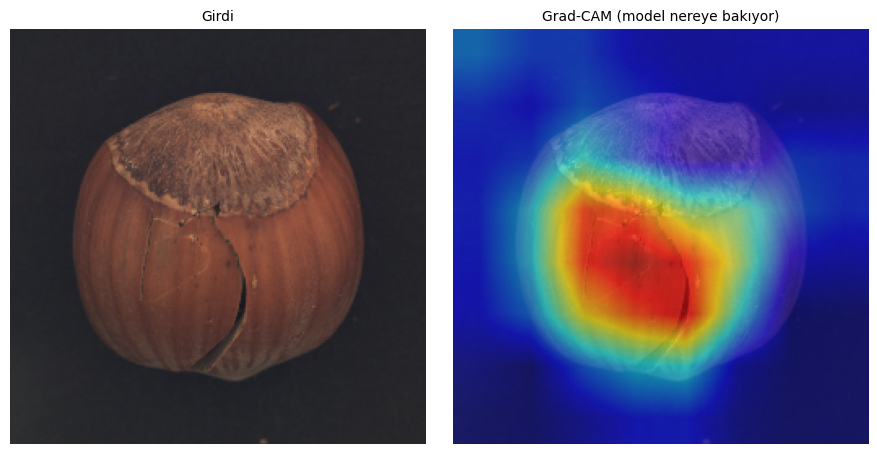

In [5]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget

target_layers = [model.encoder.layer4[-1]]
with GradCAM(model=model, target_layers=target_layers) as cam:
    targets = [SemanticSegmentationTarget(0, pred_mask)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(rgb_img)
axes[0].set_title("Girdi", fontsize=10)
axes[1].imshow(cam_image)
axes[1].set_title("Grad-CAM (model nereye bakıyor)", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Özet

Bu notebook, eğitilmiş segmentasyon modelinin tek bir görsel üzerindeki tüm akışını (tahmin + Grad-CAM açıklaması) gösterdi. Modelin başarısız olduğu örneklerin ve çok yöntemli (GradCAM/GradCAM++/EigenCAM) daha derin XAI analizinin toplu galerisi için `explainability.ipynb`'ye, tüm test seti + karşılaştırma tablosu için `src/evaluate.py` ve `src/visualize.py`'ye bakın.